# Groundwater Nitrate — Integrated Dataset EDA

**Dataset:** `groundwater_ml_integration_validation.csv`  
**Study period:** 2022–2025

---

## Research Objective

Explore the integrated groundwater nitrate dataset to assess data quality, temporal and spatial structure, environmental predictors, and readiness for machine learning.

**Guiding question:** What can the available environmental and agricultural data tell us about groundwater nitrate patterns in the Salinas Valley?
  

## 1. Data Overview & Sanity Checks

### 1.1 Load and Inspect the Integrated Dataset

**Objective:** Verify the dataset dimensions, inspect its structure, and identify potential data quality issues before exploratory analysis.


In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("groundwater_ml_integration_validation.csv")

df = pd.read_csv(data_path)

print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (5280, 49)


,gm_well_id,gm_well_category,gm_samp_collection_date,gm_latitude,gm_longitude,nitrate_mg_L,year,source_csv_row,observation_id,soil_mapped_coverage_pct,...,pct_idle_fallow_1000m_2023,pct_multicrop_1000m_2023,dist_veg_berry_m_2023,crop_map_reference_year,historical_mean_annual_precip_mm,previous_3_complete_months_precip_mm,previous_12_complete_months_precip_mm,historical_mean_temperature_c,previous_3_complete_months_temperature_c,previous_12_complete_months_temperature_c
0,AGL020000465-PRIMARY,Domestic,2022-05-04 09:40:00,35.551290,-120.600420,3.12,2022,2,GW-CSV-00002,100.0,...,NaN,NaN,NaN,NaN,347.528444,37.846,282.194,15.820988,11.796296,15.629630
1,AGL020000465-PRIMARY,Domestic,2023-06-07 11:45:00,35.551290,-120.600420,2.97,2023,3,GW-CSV-00003,100.0,...,NaN,NaN,NaN,NaN,338.429600,232.664,838.200,15.817593,13.037037,15.268519
2,AGL020000465-PRIMARY,Domestic,2024-05-16 08:00:00,35.551290,-120.600420,3.38,2024,4,GW-CSV-00004,100.0,...,NaN,NaN,NaN,2023.0,377.420909,312.420,538.226,15.727273,11.351852,15.134259
3,AGL020000465-PRIMARY,Domestic,2025-04-14 08:00:00,35.551290,-120.600420,3.14,2025,5,GW-CSV-00005,100.0,...,NaN,NaN,NaN,2023.0,384.429000,169.164,299.720,15.709877,9.962963,15.467593
4,AGL020000484-ROOS-HOMESTEAD,Domestic,2022-05-18 12:50:00,35.515854,-120.640089,3.82,2022,6,GW-CSV-00006,100.0,...,NaN,NaN,NaN,NaN,417.406667,39.370,307.848,15.368313,11.425926,15.314815


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5280 entries, 0 to 5279
Data columns (total 49 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   gm_well_id                                        5280 non-null   object 
 1   gm_well_category                                  5280 non-null   object 
 2   gm_samp_collection_date                           5280 non-null   object 
 3   gm_latitude                                       5280 non-null   float64
 4   gm_longitude                                      5280 non-null   float64
 5   nitrate_mg_L                                      5280 non-null   float64
 6   year                                              5280 non-null   int64  
 7   source_csv_row                                    5280 non-null   int64  
 8   observation_id                                    5280 non-null   object 
 9   soil_mapped_coverag

### 1.3 Missing Data Overview

**Objective:** Quantify missing values across variables and identify potential limitations for modeling.

In [3]:
missing = df.isna().sum().sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": (missing / len(df) * 100).round(1)
})

display(missing_summary[missing_summary["missing_count"] > 0])

,missing_count,missing_pct
soil_brockdepmin,3864,73.2
crop_cycles_500m_2023,3493,66.2
pct_vineyard_1000m_2023,3491,66.1
pct_idle_fallow_500m_2023,3491,66.1
pct_grain_field_pasture_500m_2023,3491,66.1
pct_idle_fallow_1000m_2023,3491,66.1
pct_grain_field_pasture_1000m_2023,3491,66.1
dist_veg_berry_m_2023,3491,66.1
pct_cropland_500m_2023,3491,66.1
pct_veg_berry_500m_2023,3491,66.1


### 1.4 Crop Data Availability by Year

**Objective:** Examine whether missing crop data varies across sampling years.

In [4]:
pd.crosstab(
    df["year"],
    df["pct_cropland_500m_2023"].notna(),
    margins=True
)

pct_cropland_500m_2023,False,True,All
year,,,
2022,1455,0,1455
2023,1298,0,1298
2024,373,879,1252
2025,365,910,1275
All,3491,1789,5280


In [5]:
pd.crosstab(
    df["year"],
    df["crop_map_reference_year"],
    dropna=False
)

crop_map_reference_year,2023.0,NaN
year,,
2022,0,1455
2023,0,1298
2024,1252,0
2025,1275,0


### 1.5 Crop Data Availability by Well Category

In [6]:
#Crop Data Availability by Well Category
recent = df[df["year"].isin([2024, 2025])]

pd.crosstab(
    recent["gm_well_category"],
    recent["pct_cropland_500m_2023"].notna(),
    margins=True
)

pct_cropland_500m_2023,False,True,All
gm_well_category,,,
Domestic,458,710,1168
Irrigation / Industrial,280,1079,1359
All,738,1789,2527


### 1.6 Spatial Pattern of Crop Data Availability

**Objective:** Explore whether missing crop data is geographically clustered among 2024–2025 groundwater observations.

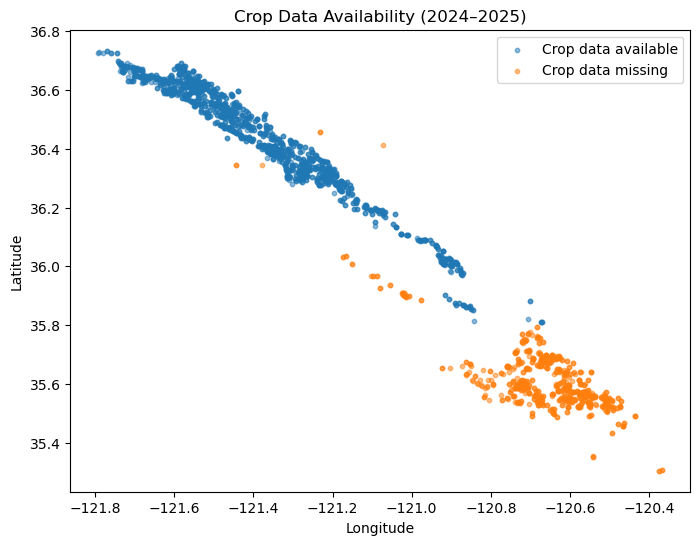

In [7]:
import matplotlib.pyplot as plt

crop_available = recent["pct_cropland_500m_2023"].notna()

plt.figure(figsize=(8, 6))

plt.scatter(
    recent.loc[crop_available, "gm_longitude"],
    recent.loc[crop_available, "gm_latitude"],
    s=10, alpha=0.5, label="Crop data available"
)

plt.scatter(
    recent.loc[~crop_available, "gm_longitude"],
    recent.loc[~crop_available, "gm_latitude"],
    s=10, alpha=0.5, label="Crop data missing"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Crop Data Availability (2024–2025)")
plt.legend()
plt.show()

### 1.7 Preliminary Interpretation of Missing Crop Data

Crop variables data availability is structured by **sampling year** and appears to be **spatially clustered**.  
No crop data are available for 2022–2023 observations, while partial crop data are available for 2024–2025 observations using a 2023 crop reference year.  
Within 2024–2025, missing crop data appear more common in areas that are likely less agriculturally intensive, suggesting that crop features may only be informative for a spatial subset of wells.

**Implication for modeling:** crop variables may be useful, but they are unlikely to support a single fully general model without careful handling of missingness and temporal validity.

## 2. Well Structure

### 2.1 Unique Wells and Repeated Measurements

**Objective:** Quantify how many unique wells are represented in the dataset and how many observations come from repeated sampling.

In [10]:
# Count unique wells and summarize repeated groundwater measurements
n_wells = df["gm_well_id"].nunique()
obs_per_well = df["gm_well_id"].value_counts()

print("Number of observations:", len(df))
print("Number of unique wells:", n_wells)
print("Average observations per well:", round(obs_per_well.mean(), 2))

display(obs_per_well.describe())

Number of observations: 5280
Number of unique wells: 1993
Average observations per well: 2.65


count    1993.000000
mean        2.649272
std         1.331922
min         1.000000
25%         1.000000
50%         3.000000
75%         4.000000
max         9.000000
Name: count, dtype: float64

### 2.2 Repeated Sampling Within Years

**Objective:** Identify wells sampled multiple times within the same year and understand the temporal structure of repeated measurements.

In [11]:
# Count how many samples each well has in each year
samples_per_well_year = df.groupby(["gm_well_id", "year"]).size()

# Count how many well-year groups have multiple samples
print("Well-year groups with multiple samples:",
      (samples_per_well_year > 1).sum())

# Show the distribution of samples per well per year
display(samples_per_well_year.value_counts().sort_index())

Well-year groups with multiple samples: 61


1    5117
2      44
3       3
4       5
5       8
6       1
Name: count, dtype: int64

### 2.3 Repeated Sampling by Well Category

**Objective:** Compare repeated sampling patterns across well categories.

In [12]:
# Count how many samples each well has in each year, keeping the well category
well_year_counts = (
    df.groupby(["gm_well_id", "gm_well_category", "year"])
      .size()
      .reset_index(name="n_samples")
)

# Create a flag for repeated sampling within the same well-year
well_year_counts["repeated_within_year"] = well_year_counts["n_samples"] > 1

# Summarize repeated sampling by well category
repeated_by_category = pd.crosstab(
    well_year_counts["gm_well_category"],
    well_year_counts["repeated_within_year"],
    margins=True
)

display(well_year_counts.head())
display(repeated_by_category)

,gm_well_id,gm_well_category,year,n_samples,repeated_within_year
0,AGL020000465-PRIMARY,Domestic,2022,1,False
1,AGL020000465-PRIMARY,Domestic,2023,1,False
2,AGL020000465-PRIMARY,Domestic,2024,1,False
3,AGL020000465-PRIMARY,Domestic,2025,1,False
4,AGL020000484-ROOS-HOMESTEAD,Domestic,2022,1,False


repeated_within_year,False,True,All
gm_well_category,,,
Domestic,2318,31,2349
Irrigation / Industrial,2799,30,2829
All,5117,61,5178


## 3. Target Variable — Groundwater Nitrate

### 3.1 Distribution & Summary Statistics

**Objective:** Examine the distribution, central tendency, variability, and extreme values of groundwater nitrate concentrations.


count    5280.000000
mean       14.310553
std        22.709797
min         0.000000
25%         1.700000
50%         4.600000
75%        16.700000
max       229.000000
Name: nitrate_mg_L, dtype: float64

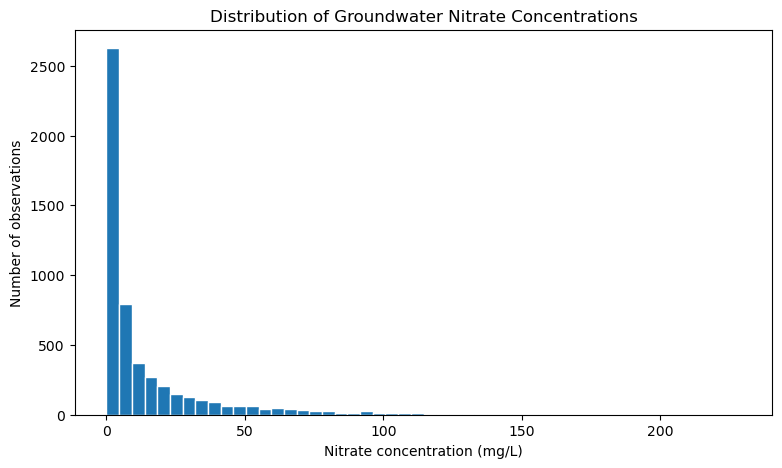

In [14]:

# Summarize nitrate concentrations across all observations
display(df["nitrate_mg_L"].describe())

# Visualize the distribution of nitrate concentrations
plt.figure(figsize=(9, 5))

plt.hist(df["nitrate_mg_L"], bins=50, edgecolor="white")

plt.xlabel("Nitrate concentration (mg/L)")
plt.ylabel("Number of observations")
plt.title("Distribution of Groundwater Nitrate Concentrations")

plt.show()



## 3. Environmental Predictors vs. Nitrate

### 3.1 Soil and Terrain Relationships

**Objective:** Identify initial associations between groundwater nitrate concentrations and soil or terrain characteristics, using one summary per well to reduce repeated-measurement bias.


In [15]:

# Select nitrate and key soil/terrain features
features = [
    "soil_slopegradwta",
    "soil_aws0150wta",
    "soil_brockdepmin",
    "elevation_m",
    "topographic_position"
]

# Summarize nitrate and environmental features by well
well_data = df.groupby("gm_well_id")[
    ["nitrate_mg_L"] + features
].median()

# Calculate Spearman correlations with nitrate
correlations = well_data[features].corrwith(
    well_data["nitrate_mg_L"], method="spearman"
)

# Show correlations and available well counts
results = pd.DataFrame({
    "spearman_r": correlations.round(3),
    "n_wells": well_data[features].notna().sum()
})

display(results.sort_values("spearman_r", ascending=False))


,spearman_r,n_wells
soil_aws0150wta,0.137,1993
topographic_position,0.069,1993
soil_brockdepmin,0.040,603
elevation_m,-0.253,1993
soil_slopegradwta,-0.361,1993


**Preliminary findings — Soil & Terrain**

- Soil slope (ρ = -0.361) and elevation (ρ = -0.253) show the strongest associations with nitrate.
- Lower slope and elevation are associated with higher nitrate concentrations.
- These relationships may reflect agricultural land use and spatial patterns rather than direct causal effects.
- Bedrock depth has limited coverage (603 wells).

**ML implication:** Retain soil and terrain predictors for further evaluation. Test whether their associations remain useful under spatially independent validation.


### 3.2 Climate Relationships

**Objective:** Explore associations between nitrate concentrations and historical or antecedent climate variables.


In [16]:
# Select historical and antecedent climate predictors
climate_features = [
    "historical_mean_annual_precip_mm",
    "previous_3_complete_months_precip_mm",
    "previous_12_complete_months_precip_mm",
    "historical_mean_temperature_c",
    "previous_3_complete_months_temperature_c",
    "previous_12_complete_months_temperature_c"
]

# Summarize climate and nitrate by well for an initial spatial comparison
climate_by_well = df.groupby("gm_well_id")[
    ["nitrate_mg_L"] + climate_features
].median()

# Calculate Spearman correlations and data availability
climate_results = pd.DataFrame({
    "spearman_r": climate_by_well[climate_features].corrwith(
        climate_by_well["nitrate_mg_L"], method="spearman"
    ).round(3),
    "n_wells": climate_by_well[climate_features].notna().sum()
})

display(climate_results.sort_values("spearman_r"))


,spearman_r,n_wells
historical_mean_annual_precip_mm,-0.418,1993
previous_12_complete_months_precip_mm,-0.173,1993
previous_3_complete_months_precip_mm,-0.098,1993
previous_12_complete_months_temperature_c,-0.029,1993
historical_mean_temperature_c,0.068,1993
previous_3_complete_months_temperature_c,0.265,1993



**Preliminary findings — Climate**

- Historical annual precipitation shows the strongest negative association with nitrate (ρ = -0.418).
- Previous 3-month temperature shows a positive association (ρ = 0.265).
- Other antecedent climate variables show weaker associations.

**ML implication:** Climate variables may provide useful predictors, but associations could reflect spatial and seasonal confounding. These results summarize differences between wells, not within-well temporal responses. Feature redundancy and predictive value must be evaluated under spatial-temporal validation.



### 3.3 Crop Relationships

**Objective:** Explore associations between agricultural land use and groundwater nitrate using 2024–2025 observations with available crop information.


In [17]:
# Select crop predictors from the 2023 agricultural map
crop_features = [
    "pct_cropland_500m_2023",
    "pct_veg_berry_500m_2023",
    "pct_grain_field_pasture_500m_2023",
    "pct_idle_fallow_500m_2023",
    "crop_cycles_500m_2023",
    "pct_vineyard_1000m_2023",
    "pct_multicrop_1000m_2023",
    "dist_veg_berry_m_2023"
]

# Use 2024–2025 observations and summarize by well
crop_by_well = (
    df[df["year"].isin([2024, 2025])]
    .groupby("gm_well_id")[["nitrate_mg_L"] + crop_features]
    .median()
)

# Calculate Spearman correlations and available well counts
crop_results = pd.DataFrame({
    "spearman_r": crop_by_well[crop_features].corrwith(
        crop_by_well["nitrate_mg_L"], method="spearman"
    ).round(3),
    "n_wells": crop_by_well[crop_features].notna().sum()
})

display(crop_results.sort_values("spearman_r"))


,spearman_r,n_wells
dist_veg_berry_m_2023,-0.080,1012
pct_cropland_500m_2023,-0.025,1012
pct_vineyard_1000m_2023,-0.022,1012
pct_grain_field_pasture_500m_2023,0.007,1012
pct_veg_berry_500m_2023,0.014,1012
pct_multicrop_1000m_2023,0.062,1012
crop_cycles_500m_2023,0.075,1011
pct_idle_fallow_500m_2023,0.078,1012



### 3.4 Feature Redundancy & Correlations

**Objective:** Identify highly correlated environmental predictors that may contain overlapping information.

**Method:** Calculate Spearman correlations between selected soil, terrain, climate, and crop features using well-level summaries.


In [18]:

# Select environmental features for an initial redundancy check
selected_features = [
    "soil_slopegradwta",
    "elevation_m",
    "soil_aws0150wta",
    "historical_mean_annual_precip_mm",
    "previous_3_complete_months_temperature_c",
    "pct_cropland_500m_2023",
    "crop_cycles_500m_2023",
    "pct_multicrop_1000m_2023"
]

# Use recent observations and summarize each feature by well
feature_data = (
    df[df["year"].isin([2024, 2025])]
    .groupby("gm_well_id")[selected_features]
    .median()
)

# Calculate correlations between predictors
feature_corr = feature_data.corr(method="spearman")

display(feature_corr.round(2))


,soil_slopegradwta,elevation_m,soil_aws0150wta,historical_mean_annual_precip_mm,previous_3_complete_months_temperature_c,pct_cropland_500m_2023,crop_cycles_500m_2023,pct_multicrop_1000m_2023
soil_slopegradwta,1.00,0.74,-0.54,0.41,-0.35,-0.56,-0.41,-0.57
elevation_m,0.74,1.00,-0.51,0.26,-0.27,-0.26,-0.32,-0.47
soil_aws0150wta,-0.54,-0.51,1.00,-0.20,0.13,0.49,0.31,0.45
historical_mean_annual_precip_mm,0.41,0.26,-0.20,1.00,-0.46,0.07,0.00,0.11
previous_3_complete_months_temperature_c,-0.35,-0.27,0.13,-0.46,1.00,0.03,0.13,0.12
pct_cropland_500m_2023,-0.56,-0.26,0.49,0.07,0.03,1.00,0.37,0.61
crop_cycles_500m_2023,-0.41,-0.32,0.31,0.00,0.13,0.37,1.00,0.77
pct_multicrop_1000m_2023,-0.57,-0.47,0.45,0.11,0.12,0.61,0.77,1.00


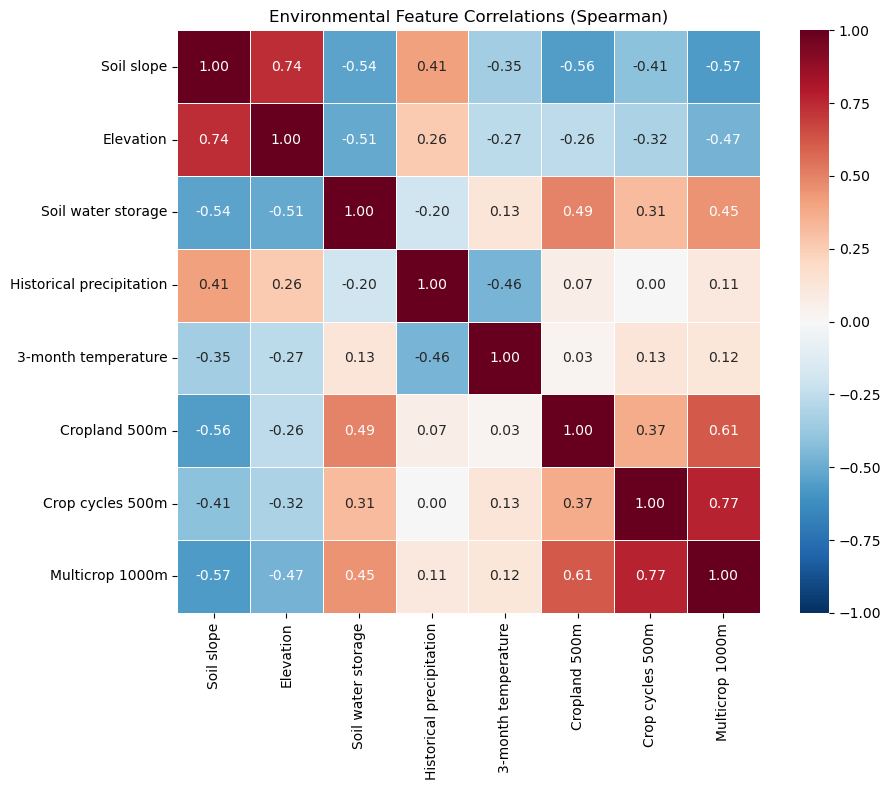

In [20]:

import seaborn as sns

# Use shorter feature names to make the plot easier to read
labels = {
    "soil_slopegradwta": "Soil slope",
    "elevation_m": "Elevation",
    "soil_aws0150wta": "Soil water storage",
    "historical_mean_annual_precip_mm": "Historical precipitation",
    "previous_3_complete_months_temperature_c": "3-month temperature",
    "pct_cropland_500m_2023": "Cropland 500m",
    "crop_cycles_500m_2023": "Crop cycles 500m",
    "pct_multicrop_1000m_2023": "Multicrop 1000m"
}

# Rename columns and rows for visualization only
plot_corr = feature_corr.rename(index=labels, columns=labels)

# Visualize Spearman correlations between environmental predictors
plt.figure(figsize=(10, 8))

sns.heatmap(
    plot_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Environmental Feature Correlations (Spearman)")
plt.tight_layout()
plt.show()


**Key Findings — Feature Redundancy**

- Crop cycles and multicrop percentage are strongly correlated (ρ = 0.77), suggesting overlapping information about agricultural intensity.
- Soil slope and elevation are also strongly correlated (ρ = 0.74), potentially reflecting the geography of Salinas Valley.
- Cropland and multicrop percentage show moderate-to-strong correlation (ρ = 0.61).
- Several environmental predictors appear to capture related spatial or agricultural characteristics.

**ML Implication:** Retain these features initially, but evaluate redundancy and their individual predictive contributions. Correlation alone is not sufficient justification for removing variables.



### 3.5 Predictor Relationships on a Comparable Well Subset

**Objective:** Compare nitrate correlations across environmental predictors using the same wells with available crop information.


In [19]:

# Summarize 2024–2025 observations by well
comparison = (
    df[df["year"].isin([2024, 2025])]
    .groupby("gm_well_id")
    .median(numeric_only=True)
)

# Keep wells with available crop information
comparison = comparison.dropna(
    subset=["pct_cropland_500m_2023", "crop_cycles_500m_2023"]
)

# Compare environmental predictors against nitrate using the same wells
comparison_features = (
    ["soil_slopegradwta", "elevation_m",
     "historical_mean_annual_precip_mm",
     "previous_3_complete_months_temperature_c"]
    + crop_features
)

print("Wells included:", len(comparison))

display(
    comparison[comparison_features]
    .corrwith(comparison["nitrate_mg_L"], method="spearman")
    .sort_values()
    .round(3)
)


Wells included: 1011


historical_mean_annual_precip_mm           -0.257
dist_veg_berry_m_2023                      -0.079
pct_cropland_500m_2023                     -0.026
pct_vineyard_1000m_2023                    -0.022
soil_slopegradwta                          -0.013
pct_grain_field_pasture_500m_2023           0.006
pct_veg_berry_500m_2023                     0.013
pct_multicrop_1000m_2023                    0.061
crop_cycles_500m_2023                       0.075
pct_idle_fallow_500m_2023                   0.079
elevation_m                                 0.228
previous_3_complete_months_temperature_c    0.325
dtype: float64

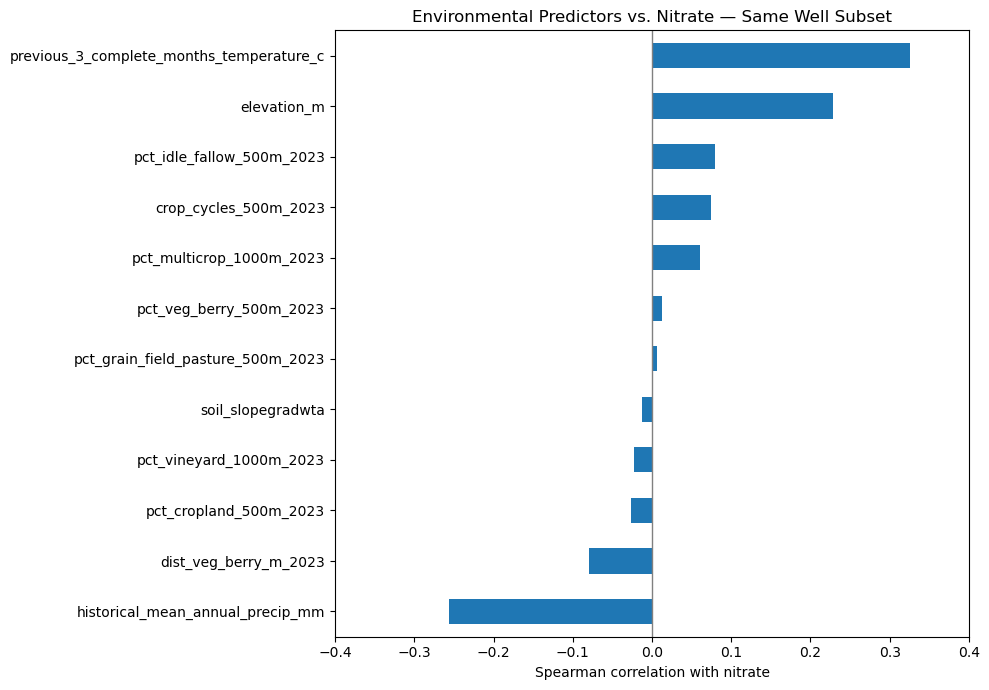

In [21]:

# Calculate nitrate correlations using the same 1,011 wells
comparison_corr = (
    comparison[comparison_features]
    .corrwith(comparison["nitrate_mg_L"], method="spearman")
    .sort_values()
)

# Visualize positive and negative associations
ax = comparison_corr.plot.barh(figsize=(10, 7))

ax.axvline(0, color="gray", linewidth=1)
ax.set_xlim(-0.4, 0.4)
ax.set_xlabel("Spearman correlation with nitrate")
ax.set_ylabel("")
ax.set_title("Environmental Predictors vs. Nitrate — Same Well Subset")

plt.tight_layout()
plt.show()



**Key Findings — Comparable Well Subset**

- Analysis was restricted to 1,011 wells with available agricultural data from 2023 and nitrate observations from 2024–2025.
- Soil slope correlation decreased substantially (ρ = -0.361 to -0.013).
- Elevation correlation changed direction (ρ = -0.253 to +0.228).
- Historical precipitation remained negatively associated with nitrate (ρ = -0.257).
- Previous 3-month temperature showed a positive association (ρ = +0.325).
- Crop variables maintained weak correlations with nitrate.

**Scientific Interpretation:** Environmental associations are sensitive to the study population and time period. Differences may reflect spatial selection, temporal variation, or other confounding factors rather than direct environmental effects.

**ML Implication:** Compare models using consistent spatial and temporal subsets, and evaluate performance with spatial-temporal validation before drawing conclusions about predictor importance.



### 3.6 Comparing Correlations Across Well Subsets

**Objective:** Visualize how nitrate correlations differ between the full well dataset (2022–2025) and the agricultural-data subset (2024–2025).

**Note:** Both the spatial sample and time period differ, so changes cannot be attributed to spatial selection alone.


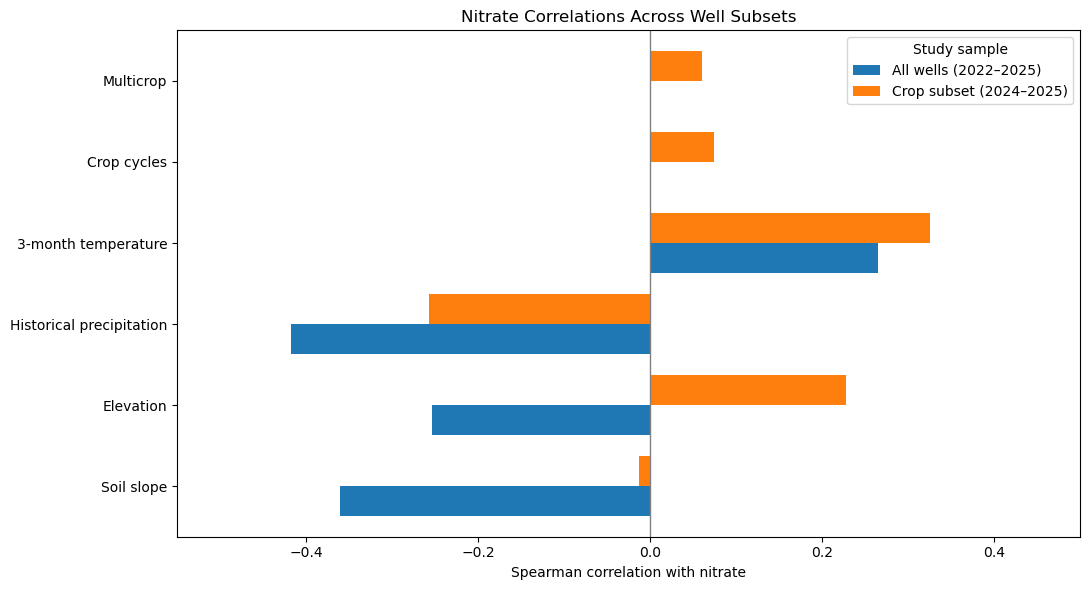

In [24]:

# Select features and assign readable labels
feature_labels = {
    "soil_slopegradwta": "Soil slope",
    "elevation_m": "Elevation",
    "historical_mean_annual_precip_mm": "Historical precipitation",
    "previous_3_complete_months_temperature_c": "3-month temperature",
    "crop_cycles_500m_2023": "Crop cycles",
    "pct_multicrop_1000m_2023": "Multicrop"
}

# Combine previous soil and climate correlation results
full_corr = pd.concat([
    results["spearman_r"],
    climate_results["spearman_r"]
])

# Compare both analyses in one table
corr_comparison = pd.DataFrame({
    "All wells (2022–2025)": full_corr,
    "Crop subset (2024–2025)": comparison_corr
}).reindex(feature_labels.keys())

corr_comparison.index = corr_comparison.index.map(feature_labels)

# Plot correlations side by side
ax = corr_comparison.plot.barh(figsize=(11, 6), width=0.75)

ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Spearman correlation with nitrate")
ax.set_ylabel("")
ax.set_title("Nitrate Correlations Across Well Subsets")
ax.set_xlim(-0.55, 0.50)
ax.legend(title="Study sample")

plt.tight_layout()
plt.show()



**Key Finding — Sample Selection**

- Correlations change substantially between the full dataset and the agricultural subset.
- Elevation changes from negative (-0.253) to positive (+0.228), while soil slope decreases from -0.361 to -0.013.
- These differences may reflect geographic sampling bias and different observation periods.
- Crop predictors show weak individual correlations with nitrate.

**Next Steps**
- Compare correlations using 2024–2025 for both populations.
- Evaluate predictors under spatial-temporal validation.
- Explore historical crop features (2021–2024) with consistent buffers and verified availability dates.
- Compare baseline and agricultural ML models on identical test observations.
      